# FedVocabHAR RealWorld HAR Phase 3C — structural baseline repair

## Exploratory agreement-triggered vocabulary growth

This structural bug-fix rerun tests the central OpenFedHAR mechanism: a novel activity is promoted only after independent integration clients discover compatible signatures. The repaired single-client baseline promotes local client clusters independently; agreement-first promotion merges compatible signatures before promotion. Both use the same fixed four-label query budget.

This is an exploratory mechanism study. Phase 3B already opened RealWorld test folds, so no result is confirmatory or may be used to retune Phase 3B. The thresholds, frozen encoder, folds, and query budget are unchanged from Phase 3C; only the baseline implementation is repaired.


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from dataclasses import dataclass,asdict
from pathlib import Path
import json,random,warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import accuracy_score,precision_recall_fscore_support,adjusted_rand_score,normalized_mutual_info_score,confusion_matrix
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

@dataclass(frozen=True)
class Config:
    project:str='/content/drive/MyDrive/FedVocabHAR'
    seed:int=42
    known_activities:tuple=('walking','running','sitting','standing')
    novel_activities:tuple=('climbingup','climbingdown','jumping','lying')
    probe_per_subject_activity:int=220
    max_candidates_per_client:int=600
    min_local_cluster_size:int=12
    min_agreeing_clients:int=2
    label_query_budget:int=4
    novelty_false_alarm_quantile:float=.02
    local_distance_quantile:float=.90
    agreement_similarity_quantile:float=.10

CFG=Config();PROJECT=Path(CFG.project);P3A=PROJECT/'artifacts'/'phase3a';P3B=PROJECT/'artifacts'/'phase3b';OUT=PROJECT/'artifacts'/'phase3c_fixed';FOLD_DIR=OUT/'folds'
OUT.mkdir(parents=True,exist_ok=True);FOLD_DIR.mkdir(parents=True,exist_ok=True)
CACHE=PROJECT/'data'/'realworld'/'cache'/'realworld_forearm_acc_w128_s64_50hz.npz';MANIFEST=P3A/'phase3a_preregistered_manifest.json'
assert CACHE.exists() and MANIFEST.exists() and all((P3B/'folds'/f'fold_{i}_models.pt').exists() for i in range(1,6))
manifest=json.loads(MANIFEST.read_text());folds=manifest['outer_folds'];assert tuple(manifest['known_activities'])==CFG.known_activities and tuple(manifest['novel_activities'])==CFG.novel_activities

def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu');seed_all(CFG.seed)
print('device:',DEVICE);print(json.dumps(asdict(CFG),indent=2))


device: cuda
{
  "project": "/content/drive/MyDrive/FedVocabHAR",
  "seed": 42,
  "known_activities": [
    "walking",
    "running",
    "sitting",
    "standing"
  ],
  "novel_activities": [
    "climbingup",
    "climbingdown",
    "jumping",
    "lying"
  ],
  "probe_per_subject_activity": 220,
  "max_candidates_per_client": 600,
  "min_local_cluster_size": 12,
  "min_agreeing_clients": 2,
  "label_query_budget": 4,
  "novelty_false_alarm_quantile": 0.02,
  "local_distance_quantile": 0.9,
  "agreement_similarity_quantile": 0.1
}


## Frozen Phase 3B representations and fold-local calibration

The Phase 3B Episodic Anchor checkpoint is frozen. Thresholds are calibrated only with the fold's training and selection subjects: a known-prototype similarity threshold identifies candidate novelty, within-class distances set the local clustering threshold, and cross-subject same-class signatures set the agreement threshold. Novel labels are never used in these steps.


In [3]:
d=np.load(CACHE);x=d['x'].astype(np.float32);subjects=d['subject'].astype(int);activities=d['activity'].astype(str)
all_activities=CFG.known_activities+CFG.novel_activities;known_to_index={a:i for i,a in enumerate(CFG.known_activities)};all_to_index={a:i for i,a in enumerate(all_activities)}

class InceptionBlock(nn.Module):
    def __init__(self,cin,width=32):
        super().__init__();self.bottleneck=nn.Conv1d(cin,width,1,bias=False);self.branches=nn.ModuleList([nn.Conv1d(width,width,k,padding=k//2,bias=False) for k in (9,19,39)])
        self.pool=nn.Sequential(nn.MaxPool1d(3,stride=1,padding=1),nn.Conv1d(cin,width,1,bias=False));self.bn=nn.BatchNorm1d(width*4)
    def forward(self,q):
        z=self.bottleneck(q);return F.relu(self.bn(torch.cat([b(z) for b in self.branches]+[self.pool(q)],1)))

class InceptionEncoder(nn.Module):
    def __init__(self,cin=4,dim=64,n_domains=6):
        super().__init__();self.block1=InceptionBlock(cin,32);self.block2=InceptionBlock(128,32);self.skip=nn.Conv1d(cin,128,1,bias=False);self.bn=nn.BatchNorm1d(128)
        self.project=nn.Sequential(nn.Linear(128,128),nn.ReLU(),nn.Linear(128,dim));self.decoder=nn.Conv1d(128,cin,1);self.domain=nn.Sequential(nn.Linear(dim,64),nn.ReLU(),nn.Linear(64,n_domains))
    def forward(self,q):
        seq=F.relu(self.bn(self.block2(self.block1(q))+self.skip(q)));return F.normalize(self.project(seq.mean(-1)),dim=1)

def safe_load(path):
    try:return torch.load(path,map_location='cpu',weights_only=False)
    except TypeError:return torch.load(path,map_location='cpu')

def encode(model,data,batch=512):
    out=[];model.eval()
    with torch.no_grad():
        for start in range(0,len(data),batch):out.append(model(torch.from_numpy(data[start:start+batch]).to(DEVICE)).cpu().numpy())
    return np.concatenate(out).astype(np.float32)

def unit(z):return z/(np.linalg.norm(z,axis=1,keepdims=True)+1e-12)

def limited_by_group(subject_set,activity_set,per_group,seed):
    rng=np.random.default_rng(seed);out=[]
    for subject in subject_set:
        for activity in activity_set:
            idx=np.where((subjects==subject)&(activities==activity))[0]
            if len(idx)>per_group:idx=rng.choice(idx,per_group,replace=False)
            out.extend(idx.tolist())
    return np.asarray(out,dtype=int)

def fold_embeddings(fold_id):
    bundle=safe_load(P3B/'folds'/f'fold_{fold_id}_models.pt');stats=bundle['stats'];model=InceptionEncoder().to(DEVICE);model.load_state_dict(bundle['anchor_state_dict']);model.eval()
    inp=np.concatenate([(x[:,:3]-stats['xyz_mean'])/stats['xyz_std'],(x[:,3:4]-stats['mag_mean'])/stats['mag_std']],1).astype(np.float32)
    return unit(encode(model,inp)),bundle

def calibrate(emb,fold):
    train=tuple(fold['train_subjects']);selection=tuple(fold['selection_subjects']);tr_idx=limited_by_group(train,CFG.known_activities,CFG.probe_per_subject_activity,CFG.seed+100*int(fold['fold']))
    se_idx=limited_by_group(selection,CFG.known_activities,CFG.probe_per_subject_activity,CFG.seed+100*int(fold['fold'])+1)
    ytr=np.asarray([known_to_index[a] for a in activities[tr_idx]]);protos=np.asarray([unit(emb[tr_idx][ytr==c].mean(0,keepdims=True))[0] for c in range(4)])
    sims=emb[se_idx]@protos.T;truth=np.asarray([known_to_index[a] for a in activities[se_idx]]);correct=sims[np.arange(len(sims)),truth]
    novelty_threshold=float(np.quantile(correct,CFG.novelty_false_alarm_quantile))
    within=[];cross=[];rng=np.random.default_rng(CFG.seed+int(fold['fold']))
    for activity in CFG.known_activities:
        for subject in selection:
            q=np.where((subjects==subject)&(activities==activity))[0]
            if len(q)>80:q=rng.choice(q,80,replace=False)
            if len(q)>1:
                z=emb[q];within.extend((1-(z@z.T))[np.triu_indices(len(z),1)].tolist())
        means=[]
        for subject in train:
            q=np.where((subjects==subject)&(activities==activity))[0]
            means.append(unit(emb[q].mean(0,keepdims=True))[0])
        for i in range(len(means)):
            for j in range(i+1,len(means)):cross.append(float(means[i]@means[j]))
    return protos,{'novelty_threshold':novelty_threshold,'local_distance':float(np.quantile(within,CFG.local_distance_quantile)),'agreement_similarity':float(np.quantile(cross,CFG.agreement_similarity_quantile))}


## Local discovery, server agreement, and selective promotion

Each integration subject supplies an unlabeled stream. A client keeps only windows that are sufficiently dissimilar from the known vocabulary, clusters those windows locally, and sends compact signatures. The server connects signatures above the fixed agreement threshold. Agreement-first promotion requires support from at least two independent clients; the single-client baseline has the same query budget but omits this requirement.

After a cluster is promoted, its medoid receives one simulated human label query. That is the only novel-label use in the operational procedure. Cluster purity and label recovery are calculated afterward for evaluation.


In [4]:
def connected_components(similarities,threshold):
    n=len(similarities);seen=set();groups=[]
    for i in range(n):
        if i in seen:continue
        stack=[i];seen.add(i);group=[]
        while stack:
            q=stack.pop();group.append(q)
            for j in np.where(similarities[q]>=threshold)[0]:
                if j not in seen:seen.add(int(j));stack.append(int(j))
        groups.append(group)
    return groups

def cluster_labels(z,distance):
    if len(z)<2:return np.zeros(len(z),dtype=int)
    try:return AgglomerativeClustering(n_clusters=None,distance_threshold=distance,metric='cosine',linkage='average').fit_predict(z)
    except TypeError:return AgglomerativeClustering(n_clusters=None,distance_threshold=distance,affinity='cosine',linkage='average').fit_predict(z)

def local_signatures(emb,clients,known_prototypes,calibration,seed):
    rng=np.random.default_rng(seed);rows=[];candidate_truth=[];candidate_cluster=[]
    for subject in clients:
        # The client stream contains both known and novel activity windows. Activity identities
        # are retained only in the audit fields after the operational discovery decisions.
        idx=np.where(subjects==subject)[0]
        candidates=idx[(emb[idx]@known_prototypes.T).max(1)<calibration['novelty_threshold']]
        if len(candidates)>CFG.max_candidates_per_client:candidates=rng.choice(candidates,CFG.max_candidates_per_client,replace=False)
        labels=cluster_labels(emb[candidates],calibration['local_distance'])
        for label in np.unique(labels):
            members=np.where(labels==label)[0]
            if len(members)<CFG.min_local_cluster_size:continue
            window_idx=candidates[members];z=emb[window_idx];signature=unit(z.mean(0,keepdims=True))[0];medoid=window_idx[np.argmax(z@signature)]
            truth=activities[window_idx];values,counts=np.unique(truth,return_counts=True);dominant=str(values[np.argmax(counts)])
            rows.append({'client':int(subject),'local_cluster':int(label),'signature':signature,'windows':window_idx.tolist(),'medoid':int(medoid),'query_label':str(activities[medoid]),'dominant_label':dominant,'purity':float(counts.max()/counts.sum()),'size':int(len(window_idx))})
            candidate_truth.extend(truth.tolist());candidate_cluster.extend([f'{subject}:{label}']*len(window_idx))
    return rows,np.asarray(candidate_truth),np.asarray(candidate_cluster)

def finalize_promotions(candidates):
    queried=sorted(candidates,key=lambda r:r['support'],reverse=True)[:CFG.label_query_budget]
    promoted=[entry for entry in queried if entry['label'] not in CFG.known_activities]
    dedup=[];seen=set()
    for entry in promoted:
        if entry['label'] not in seen:dedup.append(entry);seen.add(entry['label'])
    return dedup,len(queried)

def promote_agreement_first(signatures,calibration):
    if not signatures:return [],[],0
    z=np.asarray([r['signature'] for r in signatures]);groups=connected_components(z@z.T,calibration['agreement_similarity']);promoted=[];audit=[]
    for group in groups:
        members=[signatures[i] for i in group];clients=set(r['client'] for r in members);support=sum(r['size'] for r in members)
        if len(clients)<CFG.min_agreeing_clients:continue
        signature=unit(np.stack([r['signature'] for r in members]).mean(0,keepdims=True))[0]
        medoids=np.asarray([r['medoid'] for r in members]);query=medoids[np.argmax(np.asarray([signature@signatures[i]['signature'] for i in group]))]
        promoted.append({'signature':signature,'label':str(activities[query]),'clients':sorted(clients),'support':int(support),'query_window':int(query),'dominant_labels':[r['dominant_label'] for r in members],'purity':float(np.average([r['purity'] for r in members],weights=[r['size'] for r in members]))})
    dedup,queries=finalize_promotions(promoted)
    return dedup,groups,queries

def promote_single_client(signatures):
    candidates=[]
    for entry in signatures:
        candidates.append({'signature':entry['signature'],'label':entry['query_label'],'clients':[entry['client']],'support':entry['size'],
          'query_window':entry['medoid'],'dominant_labels':[entry['dominant_label']],'purity':entry['purity']})
    dedup,queries=finalize_promotions(candidates)
    return dedup,[[i] for i in range(len(signatures))],queries

def classifier_metrics(emb,known_idx,novel_entries,test_idx):
    yknown=np.asarray([known_to_index[a] for a in activities[known_idx]]);known_prototypes=np.asarray([unit(emb[known_idx][yknown==c].mean(0,keepdims=True))[0] for c in range(4)])
    labels=list(CFG.known_activities)+[r['label'] for r in novel_entries];prototypes=[*known_prototypes]+[r['signature'] for r in novel_entries]
    pred=np.asarray(labels)[(emb[test_idx]@np.asarray(prototypes).T).argmax(1)];true=activities[test_idx]
    f1=precision_recall_fscore_support(true,pred,labels=list(all_activities),zero_division=0)[2]
    novel_f1=f1[4:];return {'combined_macro_f1':float(f1.mean()),'novel_macro_f1':float(novel_f1.mean()),'known_macro_f1':float(f1[:4].mean()),'worst_novel_f1':float(novel_f1.min()),'pred':pred,'true':true,'per_class_f1':f1}


## Five-fold exploratory mechanism evaluation

The only operational label queries occur after promotion. Test labels are used exclusively after all promoted entries are fixed, to score the frozen vocabulary. A fold writes a compact JSON result and is skipped on a restart.


In [5]:
for fold in folds:
    fold_id=int(fold['fold']);result_path=FOLD_DIR/f'fold_{fold_id}_complete.json'
    if result_path.exists():print('fold',fold_id,'already complete; skipping');continue
    emb,bundle=fold_embeddings(fold_id);known_prototypes,calibration=calibrate(emb,fold)
    signatures,candidate_truth,candidate_cluster=local_signatures(emb,tuple(fold['integration_subjects']),known_prototypes,calibration,CFG.seed+fold_id)
    known_idx=limited_by_group(tuple(fold['train_subjects'])+tuple(fold['selection_subjects']),CFG.known_activities,CFG.probe_per_subject_activity,CFG.seed+700+fold_id)
    test_idx=np.where(np.isin(subjects,fold['test_subjects']))[0]
    rows=[];entry_rows=[]
    for method in ('single_client','agreement_first'):
        if method=='single_client':entries,groups,queries=promote_single_client(signatures)
        else:entries,groups,queries=promote_agreement_first(signatures,calibration)
        metrics=classifier_metrics(emb,known_idx,entries,test_idx)
        recovered=len(set(e['label'] for e in entries)&set(CFG.novel_activities));query_precision=float(np.mean([e['label']==max(set(e['dominant_labels']),key=e['dominant_labels'].count) for e in entries])) if entries else 0.0
        row={'fold':fold_id,'method':method,'local_signatures':len(signatures),'agreement_components':len(groups),'promoted_entries':len(entries),'label_queries':queries,'recovered_novel_activities':recovered,'novel_recovery':recovered/len(CFG.novel_activities),'mean_entry_purity':float(np.mean([e['purity'] for e in entries])) if entries else 0.0,'query_label_precision':query_precision,'candidate_cluster_ari':float(adjusted_rand_score(candidate_truth,candidate_cluster)) if len(candidate_truth) else 0.0,'candidate_cluster_nmi':float(normalized_mutual_info_score(candidate_truth,candidate_cluster)) if len(candidate_truth) else 0.0,**{k:v for k,v in metrics.items() if k not in ('pred','true','per_class_f1')}}
        rows.append(row)
        for number,e in enumerate(entries,1):entry_rows.append({'fold':fold_id,'method':method,'entry':number,'label_query_result':e['label'],'clients':','.join(map(str,e['clients'])),'client_count':len(e['clients']),'support':e['support'],'purity':e['purity'],'dominant_labels':'|'.join(e['dominant_labels'])})
    payload={'fold':fold,'calibration':calibration,'results':rows,'entries':entry_rows,'n_local_signatures':len(signatures)};result_path.write_text(json.dumps(payload,indent=2));print('completed fold',fold_id,calibration)


completed fold 1 {'novelty_threshold': 0.6639810800552368, 'local_distance': 0.20903418660163872, 'agreement_similarity': 0.8902801990509033}
completed fold 2 {'novelty_threshold': 0.45390334725379944, 'local_distance': 0.415741091966629, 'agreement_similarity': 0.8830231964588166}
completed fold 3 {'novelty_threshold': 0.6133874654769897, 'local_distance': 0.23169264197349543, 'agreement_similarity': 0.8953942000865937}
completed fold 4 {'novelty_threshold': 0.6225662231445312, 'local_distance': 0.22161706686019897, 'agreement_similarity': 0.8933271527290344}
completed fold 5 {'novelty_threshold': 0.16975978016853333, 'local_distance': 0.5462456405162811, 'agreement_similarity': 0.834448516368866}


## Results, exploratory decision, and paper-facing evidence

Agreement-first is supported when it reduces label queries or low-purity promotions while maintaining or improving recovery and combined-vocabulary F1 over single-client promotion. This is an exploratory decision rule, not a newly retrofitted confirmatory gate.


In [6]:
assert all((FOLD_DIR/f'fold_{i}_complete.json').exists() for i in range(1,6)),'Not all folds are complete; rerun the previous cell'
payloads=[json.loads((FOLD_DIR/f'fold_{i}_complete.json').read_text()) for i in range(1,6)]
results=pd.DataFrame([r for p in payloads for r in p['results']]);entries=pd.DataFrame([r for p in payloads for r in p['entries']]);calibration=pd.DataFrame([{'fold':p['fold']['fold'],**p['calibration'],'local_signatures':p['n_local_signatures']} for p in payloads])
results.to_csv(OUT/'phase3c_fixed_fold_results.csv',index=False);entries.to_csv(OUT/'phase3c_fixed_promoted_entries.csv',index=False);calibration.to_csv(OUT/'phase3c_fixed_calibration.csv',index=False)
summary=results.groupby('method').mean(numeric_only=True);single=results[results.method=='single_client'].set_index('fold');agreement=results[results.method=='agreement_first'].set_index('fold');delta=(agreement.select_dtypes('number')-single.select_dtypes('number')).reset_index();delta.to_csv(OUT/'phase3c_fixed_agreement_minus_single.csv',index=False)
agreement_support={'strictly_reduced_queries':bool((agreement.label_queries<single.label_queries).any()),'higher_mean_entry_purity':bool(agreement.mean_entry_purity.mean()>single.mean_entry_purity.mean()),'noninferior_novel_recovery':bool(agreement.novel_recovery.mean()>=single.novel_recovery.mean()),'noninferior_combined_f1':bool(agreement.combined_macro_f1.mean()>=single.combined_macro_f1.mean())}
decision={'phase':'Phase 3C structural baseline repair','status':'Exploratory; RealWorld Phase 3B test folds were previously opened.','repair':'Single-client promotion now promotes local clusters without server-side agreement merging. All thresholds and experimental settings are unchanged.','method':'Agreement-first promotion requires two independent integration clients and one medoid label query per promoted entry.','summary':json.loads(summary.to_json(orient='index')),'agreement_minus_single_mean':{k:float(v) for k,v in delta.mean(numeric_only=True).to_dict().items() if k!='fold'},'agreement_support':agreement_support,'next_requirement':'Replicate the locked mechanism and thresholds on a third dataset before making confirmatory claims.','config':asdict(CFG)}
(OUT/'phase3c_fixed_exploratory_decision.json').write_text(json.dumps(decision,indent=2));display(results.round(4));print(json.dumps(decision,indent=2))


,fold,method,local_signatures,agreement_components,promoted_entries,label_queries,recovered_novel_activities,novel_recovery,mean_entry_purity,query_label_precision,candidate_cluster_ari,candidate_cluster_nmi,combined_macro_f1,novel_macro_f1,known_macro_f1,worst_novel_f1
0,1,single_client,2,2,1,2,1,0.25,0.6522,1.0,0.4164,0.3960,0.3264,0.0195,0.6333,0.0
1,1,agreement_first,2,1,1,1,1,0.25,0.7209,0.0,0.4164,0.3960,0.3256,0.0182,0.6330,0.0
2,2,single_client,0,0,0,0,0,0.00,0.0000,0.0,0.0000,0.0000,0.3492,0.0000,0.6983,0.0
3,2,agreement_first,0,0,0,0,0,0.00,0.0000,0.0,0.0000,0.0000,0.3492,0.0000,0.6983,0.0
4,3,single_client,3,3,2,3,2,0.50,0.7067,1.0,0.2894,0.3029,0.4987,0.3043,0.6930,0.0
5,3,agreement_first,3,1,1,1,1,0.25,0.7586,1.0,0.2894,0.3029,0.3828,0.0722,0.6934,0.0
6,4,single_client,3,3,2,3,2,0.50,0.9750,1.0,0.6282,0.5620,0.4201,0.2600,0.5802,0.0
7,4,agreement_first,3,1,1,1,1,0.25,0.9223,1.0,0.6282,0.5620,0.3162,0.0483,0.5842,0.0
8,5,single_client,0,0,0,0,0,0.00,0.0000,0.0,0.0000,0.0000,0.3415,0.0000,0.6830,0.0
9,5,agreement_first,0,0,0,0,0,0.00,0.0000,0.0,0.0000,0.0000,0.3415,0.0000,0.6830,0.0


{
  "phase": "Phase 3C structural baseline repair",
  "status": "Exploratory; RealWorld Phase 3B test folds were previously opened.",
  "repair": "Single-client promotion now promotes local clusters without server-side agreement merging. All thresholds and experimental settings are unchanged.",
  "method": "Agreement-first promotion requires two independent integration clients and one medoid label query per promoted entry.",
  "summary": {
    "agreement_first": {
      "fold": 3.0,
      "local_signatures": 1.6,
      "agreement_components": 0.6,
      "promoted_entries": 0.6,
      "label_queries": 0.6,
      "recovered_novel_activities": 0.6,
      "novel_recovery": 0.15,
      "mean_entry_purity": 0.4803762039,
      "query_label_precision": 0.4,
      "candidate_cluster_ari": 0.2668082996,
      "candidate_cluster_nmi": 0.25220612,
      "combined_macro_f1": 0.3430580547,
      "novel_macro_f1": 0.0277349108,
      "known_macro_f1": 0.6583811987,
      "worst_novel_f1": 0.0
    },

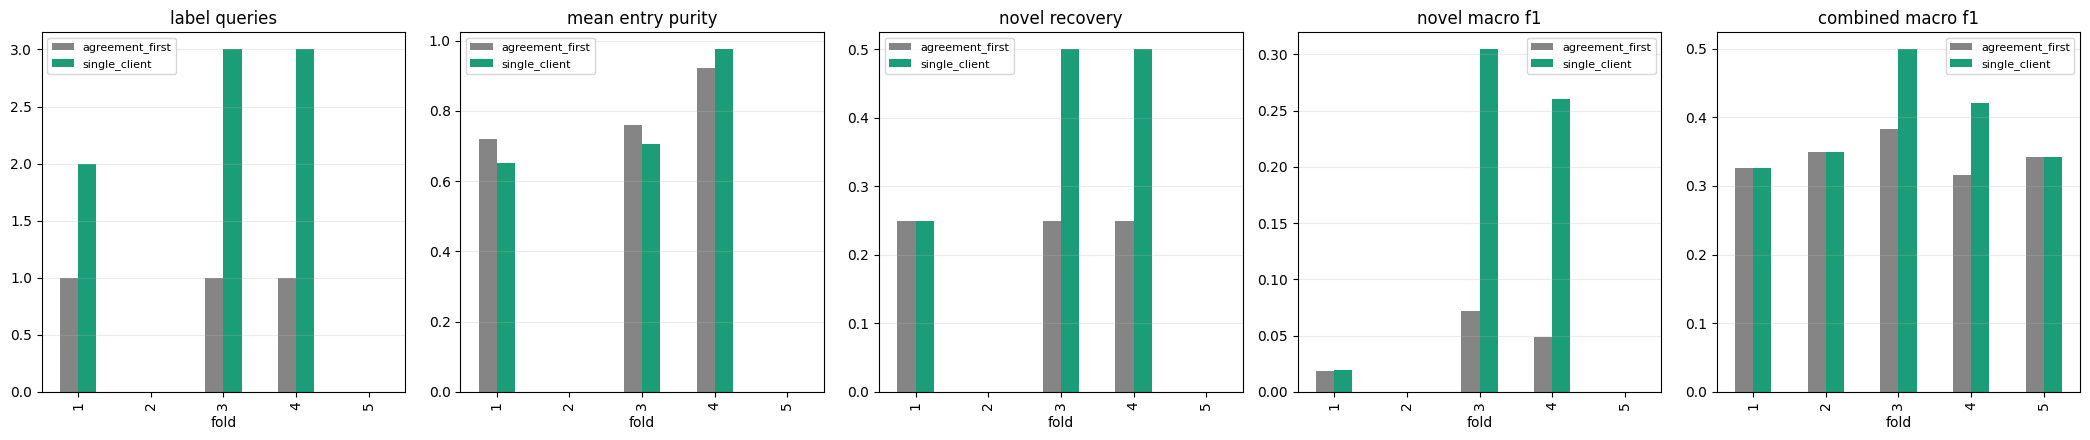

# FedVocabHAR RealWorld Phase 3C Structural Baseline Repair Report

## Status

This is an exploratory mechanism study. The single-client baseline was repaired to prevent any server-side signature merging. Thresholds, frozen encoders, folds, and query budgets were unchanged.

## Agreement-first versus single-client promotion


### agreement_first

- Label queries: 0.60
- Entry purity: 0.4804
- Novel recovery: 0.1500
- Novel macro-F1: 0.0277
- Combined macro-F1: 0.3431

### single_client

- Label queries: 1.60
- Entry purity: 0.4668
- Novel recovery: 0.2500
- Novel macro-F1: 0.1168
- Combined macro-F1: 0.3872

## Mechanism checks

- strictly_reduced_queries: **True**
- higher_mean_entry_purity: **True**
- noninferior_novel_recovery: **False**
- noninferior_combined_f1: **False**

The next scientific step is a preregistered replication on a third HAR dataset with all thresholds and the agreement policy locked before test data are opened.



In [7]:
metrics=['label_queries','mean_entry_purity','novel_recovery','novel_macro_f1','combined_macro_f1'];fig,axes=plt.subplots(1,5,figsize=(21,4.5))
for ax,metric in zip(axes,metrics):
    table=results.pivot(index='fold',columns='method',values=metric);table.plot(kind='bar',ax=ax,color=['#858585','#1b9e77']);ax.set_title(metric.replace('_',' '));ax.grid(axis='y',alpha=.25);ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/'phase3c_fixed_agreement_comparison.png',dpi=180,bbox_inches='tight');plt.show()

report=f"""# FedVocabHAR RealWorld Phase 3C Structural Baseline Repair Report

## Status

This is an exploratory mechanism study. The single-client baseline was repaired to prevent any server-side signature merging. Thresholds, frozen encoders, folds, and query budgets were unchanged.

## Agreement-first versus single-client promotion

"""
for method in summary.index:
    row=summary.loc[method];report+=f"\n### {method}\n\n- Label queries: {row.label_queries:.2f}\n- Entry purity: {row.mean_entry_purity:.4f}\n- Novel recovery: {row.novel_recovery:.4f}\n- Novel macro-F1: {row.novel_macro_f1:.4f}\n- Combined macro-F1: {row.combined_macro_f1:.4f}\n"
report+='\n## Mechanism checks\n\n'
for name,value in agreement_support.items():report+=f'- {name}: **{value}**\n'
report+='\nThe next scientific step is a preregistered replication on a third HAR dataset with all thresholds and the agreement policy locked before test data are opened.\n'
(OUT/'FedVocabHAR_RealWorld_Phase3C_FIXED_Exploratory_Report.md').write_text(report);print(report)


## Next step

Use Phase 3C only to diagnose whether agreement-first promotion is worth carrying forward. Before manuscript claims, lock this implementation and replicate it on a third dataset such as PAMAP2 or Opportunity with a genuinely sealed test split.
